**Assessment - 2**

In [0]:
import re
from pyspark.sql import functions as F
from pyspark.sql.types import (
    StructType, StructField, IntegerType, StringType, DoubleType, TimestampType)

CATALOG = "sasi_008"
SCHEMA = "default"
VOLUME = "training_files"
FOLDER = "water_network"

In [0]:
BASE_PATH = f"/Volumes/{CATALOG}/{SCHEMA}/{VOLUME}/{FOLDER}"
NAMESPACE = f"{CATALOG}.{SCHEMA}"
print("Reading files from:", BASE_PATH)

Reading files from: /Volumes/sasi_008/default/training_files/water_network


In [0]:
required_files = [
    "water_meter_readings.csv",
    "water_zones.json",
    "water_service_requests.csv",
    "water_reading_changes.csv",
    "water_readings_incremental.csv"]
available_files = {x.name.rstrip("/") for x in dbutils.fs.ls(BASE_PATH)}
missing_files = sorted(set(required_files) - available_files)
if missing_files:
    raise FileNotFoundError(f"Missing files in {BASE_PATH}: {missing_files}")
print("All five source files are available.")

spark.sql(f"USE CATALOG `{CATALOG}`")
spark.sql(f"USE SCHEMA `{SCHEMA}`")

All five source files are available.


DataFrame[]

In [0]:
reading_schema = StructType([
    StructField("reading_id", IntegerType(), True),
    StructField("meter_id", StringType(), True),
    StructField("zone_id", StringType(), True),
    StructField("reading_time", TimestampType(), True),
    StructField("flow_lpm", DoubleType(), True),
    StructField("pressure_bar", DoubleType(), True),
    StructField("chlorine_mg_l", DoubleType(), True),
    StructField("consumption_liters", IntegerType(), True),
    StructField("reading_status", StringType(), True),
    StructField("source_system", StringType(), True)])

def read_readings(file_name):
    return (spark.read.format("csv")
        .option("header", "true")
        .option("timestampFormat", "yyyy-MM-dd HH:mm:ss")
        .schema(reading_schema)
        .load(f"{BASE_PATH}/{file_name}"))

def save_delta(df, table_name):
    (df.write.format("delta")
        .mode("overwrite")
        .option("overwriteSchema", "true")
        .saveAsTable(f"{NAMESPACE}.{table_name}"))

In [0]:

source_readings = read_readings("water_meter_readings.csv")
save_delta(source_readings, "water_meter_readings_source")
save_delta(source_readings, "water_meter_readings_work")
save_delta(read_readings("water_reading_changes.csv"), "water_reading_changes")
save_delta(read_readings("water_readings_incremental.csv"), "water_readings_incremental_staging")

In [0]:
zones_raw = spark.read.json(f"{BASE_PATH}/water_zones.json")
save_delta(zones_raw, "water_zones_raw")
zones = zones_raw.select(
    "zone_id", "zone_name",
    F.col("location.city").alias("city"),
    F.col("location.district").alias("district"),
    "zone_type", "daily_capacity_liters", "active", "commissioned_on")
save_delta(zones, "water_zones")

In [0]:
request_schema = StructType([
    StructField("request_id", IntegerType(), True),
    StructField("meter_id", StringType(), True),
    StructField("zone_id", StringType(), True),
    StructField("reported_at", TimestampType(), True),
    StructField("issue_type", StringType(), True),
    StructField("priority", StringType(), True),
    StructField("estimated_cost", DoubleType(), True),
    StructField("work_status", StringType(), True)])
requests = (spark.read.format("csv")
    .option("header", "true")
    .option("timestampFormat", "yyyy-MM-dd HH:mm:ss")
    .schema(request_schema)
    .load(f"{BASE_PATH}/water_service_requests.csv"))
save_delta(requests, "water_service_requests")


In [0]:
for table_name in [
    "water_meter_readings_source", "water_meter_readings_work",
    "water_zones_raw", "water_zones", "water_service_requests",
    "water_reading_changes", "water_readings_incremental_staging"]:
    print(f"{NAMESPACE}.{table_name}: {spark.table(f'{NAMESPACE}.{table_name}').count()} rows")
print("SETUP COMPLETE. Do not rerun after beginning exercises or pipeline ingestion.")


sasi_008.default.water_meter_readings_source: 157 rows
sasi_008.default.water_meter_readings_work: 157 rows
sasi_008.default.water_zones_raw: 11 rows
sasi_008.default.water_zones: 11 rows
sasi_008.default.water_service_requests: 36 rows
sasi_008.default.water_reading_changes: 12 rows
sasi_008.default.water_readings_incremental_staging: 18 rows
SETUP COMPLETE. Do not rerun after beginning exercises or pipeline ingestion.


In [0]:
%sql
DESCRIBE TABLE sasi_008.default.water_meter_readings_source;

col_name,data_type,comment
reading_id,int,null
meter_id,string,null
zone_id,string,null
reading_time,timestamp,null
flow_lpm,double,null
pressure_bar,double,null
chlorine_mg_l,double,null
consumption_liters,int,null
reading_status,string,null
source_system,string,null


In [0]:
%sql
SELECT COUNT(*) AS total_readings
FROM sasi_008.default.water_meter_readings_source;

total_readings
157


In [0]:
%sql
SELECT reading_id, meter_id, zone_id, reading_time, consumption_liters
FROM sasi_008.default.water_meter_readings_source
WHERE reading_status = 'Valid';

reading_id,meter_id,zone_id,reading_time,consumption_liters
1001,M001,W01,2026-10-01T07:00:00.000Z,2365
1002,M002,W02,2026-10-01T08:10:00.000Z,3545
1003,M003,W03,2026-10-01T09:20:00.000Z,548
1004,M004,W04,2026-10-01T10:00:00.000Z,2871
1006,M006,W06,2026-10-01T12:20:00.000Z,2171
1007,M007,W07,2026-10-01T13:00:00.000Z,4167
1008,M008,W08,2026-10-01T14:10:00.000Z,3621
1009,M009,W09,2026-10-01T15:20:00.000Z,1609
1010,M010,W10,2026-10-01T16:00:00.000Z,1829
1011,M011,W01,2026-10-02T07:10:00.000Z,313


In [0]:
%sql
SELECT *
FROM sasi_008.default.water_meter_readings_source
WHERE pressure_bar < 2.5
ORDER BY pressure_bar ASC;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1071,M011,W01,2026-10-08T07:10:00.000Z,10.9,1.8,0.8,647,Valid,SmartMeter
1064,M004,W04,2026-10-07T10:00:00.000Z,20.3,1.82,0.84,708,Valid,Gateway
1024,M024,W04,2026-10-03T10:20:00.000Z,44.5,1.83,1.25,2085,Valid,FieldApp
1116,M026,W06,2026-10-12T12:10:00.000Z,28.9,1.84,0.36,1692,Valid,SmartMeter
1133,M013,W03,2026-10-14T09:00:00.000Z,15.6,1.86,0.8,900,Valid,Gateway
1028,M028,W08,2026-10-03T14:00:00.000Z,15.0,1.9,0.94,452,Valid,Gateway
1032,M002,W02,2026-10-04T08:10:00.000Z,34.4,1.92,0.88,1006,Valid,SmartMeter
1051,M021,W01,2026-10-06T07:20:00.000Z,72.0,1.93,0.27,1818,Valid,FieldApp
1052,M022,W02,2026-10-06T08:00:00.000Z,74.0,1.94,0.21,4669,Valid,Gateway
1044,M014,W04,2026-10-05T10:10:00.000Z,79.3,1.95,1.23,2661,Valid,SmartMeter


In [0]:
%sql
SELECT *
FROM sasi_008.default.water_meter_readings_source
WHERE flow_lpm BETWEEN 20 AND 50
  AND source_system IN ('Gateway', 'SmartMeter');

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1001,M001,W01,2026-10-01T07:00:00.000Z,39.1,3.56,0.75,2365,Valid,Gateway
1014,M014,W04,2026-10-02T10:10:00.000Z,22.4,4.73,0.5,1108,Valid,SmartMeter
1017,M017,W07,2026-10-02T13:10:00.000Z,28.0,3.77,1.08,1318,Valid,SmartMeter
1019,M019,W09,2026-10-02T15:00:00.000Z,23.0,4.34,0.28,1091,Valid,Gateway
1022,M022,W02,2026-10-03T08:00:00.000Z,32.5,3.35,0.6,1706,Suspect,Gateway
1032,M002,W02,2026-10-04T08:10:00.000Z,34.4,1.92,0.88,1006,Valid,SmartMeter
1047,M017,W07,2026-10-05T13:10:00.000Z,28.8,3.23,0.91,1258,Valid,SmartMeter
1049,M019,W09,2026-10-05T15:00:00.000Z,21.4,2.43,0.47,611,Valid,Gateway
1050,M020,W10,2026-10-05T16:10:00.000Z,37.2,3.91,1.02,2154,Valid,SmartMeter
1056,M026,W06,2026-10-06T12:10:00.000Z,27.2,2.69,0.68,1131,Suspect,SmartMeter


In [0]:
%sql
SELECT reading_status, COUNT(*) AS reading_count
FROM sasi_008.default.water_meter_readings_source
GROUP BY reading_status
ORDER BY reading_status;

reading_status,reading_count
Rejected,9
Suspect,11
Valid,137


In [0]:
%sql
SELECT z.zone_name, z.district, r.meter_id, r.consumption_liters
FROM sasi_008.default.water_meter_readings_source r
LEFT JOIN sasi_008.default.water_zones z
  ON r.zone_id = z.zone_id;

zone_name,district,meter_id,consumption_liters
Old City,Central,M001,2365
Hill View,North,M002,3545
Market District,Central,M003,548
Lake Side,West,M004,2871
University Quarter,East,M005,2656
Industrial Estate,South,M006,2171
Garden Colony,North,M007,4167
Transit Hub,East,M008,3621
Riverfront,West,M009,1609
South Extension,South,M010,1829


In [0]:
%sql
SELECT r.*
FROM sasi_008.default.water_meter_readings_source r
LEFT ANTI JOIN sasi_008.default.water_zones z
  ON r.zone_id = z.zone_id;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1154,M999,W99,2026-10-16T11:00:00.000Z,24.5,3.0,0.45,1150,Valid,FieldApp
1156,M012,null,2026-10-16T12:30:00.000Z,28.0,3.1,0.52,870,Valid,Gateway


In [0]:
%sql
SELECT z.zone_id, z.zone_name, z.district
FROM sasi_008.default.water_zones z
LEFT ANTI JOIN sasi_008.default.water_meter_readings_source r
  ON z.zone_id = r.zone_id;

zone_id,zone_name,district
W11,New Development,West


In [0]:
%sql
SELECT z.zone_id, z.zone_name,
       SUM(r.consumption_liters) AS total_valid_consumption,
       AVG(r.pressure_bar) AS average_pressure_bar,
       COUNT(*) AS reading_count
FROM sasi_008.default.water_meter_readings_source r
JOIN sasi_008.default.water_zones z ON r.zone_id = z.zone_id
WHERE r.reading_status = 'Valid'
  AND r.consumption_liters > 0
GROUP BY z.zone_id, z.zone_name
ORDER BY total_valid_consumption DESC;

zone_id,zone_name,total_valid_consumption,average_pressure_bar,reading_count
W03,Market District,35665,3.019999999999999,13
W08,Transit Hub,33689,2.8657142857142857,14
W05,University Quarter,28717,3.632857142857143,14
W10,South Extension,27808,3.717692307692307,14
W07,Garden Colony,25104,3.5700000000000003,13
W02,Hill View,24120,3.3061538461538458,13
W01,Old City,23107,3.423076923076923,13
W09,Riverfront,20894,3.5469230769230773,13
W04,Lake Side,20781,3.2371428571428575,14
W06,Industrial Estate,20212,3.160769230769231,13


In [0]:
%sql
WITH meter_totals AS (
  SELECT z.district, r.meter_id,
         SUM(r.consumption_liters) AS total_consumption
  FROM sasi_008.default.water_meter_readings_source r
  JOIN sasi_008.default.water_zones z ON r.zone_id = z.zone_id
  WHERE r.reading_status = 'Valid' AND r.consumption_liters > 0
  GROUP BY z.district, r.meter_id)
SELECT district, meter_id, total_consumption,
       DENSE_RANK() OVER (PARTITION BY district ORDER BY total_consumption DESC) AS district_rank
FROM meter_totals
ORDER BY district, district_rank, meter_id;

district,meter_id,total_consumption,district_rank
Central,M023,17814,1
Central,M001,11416,2
Central,M003,10447,3
Central,M013,7404,4
Central,M021,7395,5
Central,M011,4296,6
East,M008,14095,1
East,M018,10660,2
East,M025,10536,3
East,M015,9807,4


In [0]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from delta.tables import DeltaTable

CATALOG = "sasi_008"
SCHEMA = "default"
NS = f"{CATALOG}.{SCHEMA}"

In [0]:
readings = spark.table(f"{NS}.water_meter_readings_source")
zones = spark.table(f"{NS}.water_zones")
readings.printSchema()
zones.printSchema()

root
 |-- reading_id: integer (nullable = true)
 |-- meter_id: string (nullable = true)
 |-- zone_id: string (nullable = true)
 |-- reading_time: timestamp (nullable = true)
 |-- flow_lpm: double (nullable = true)
 |-- pressure_bar: double (nullable = true)
 |-- chlorine_mg_l: double (nullable = true)
 |-- consumption_liters: integer (nullable = true)
 |-- reading_status: string (nullable = true)
 |-- source_system: string (nullable = true)

root
 |-- zone_id: string (nullable = true)
 |-- zone_name: string (nullable = true)
 |-- city: string (nullable = true)
 |-- district: string (nullable = true)
 |-- zone_type: string (nullable = true)
 |-- daily_capacity_liters: long (nullable = true)
 |-- active: boolean (nullable = true)
 |-- commissioned_on: string (nullable = true)



In [0]:
high_flow_valid = (readings
    .filter((F.col("reading_status") == "Valid") & (F.col("flow_lpm") >= 60))
    .select("reading_id", "meter_id", "zone_id", "flow_lpm", "pressure_bar", "consumption_liters")
    .orderBy(F.col("flow_lpm").desc()))
display(high_flow_valid)

reading_id,meter_id,zone_id,flow_lpm,pressure_bar,consumption_liters
1110,M020,W10,84.0,4.45,3360
1106,M016,W06,83.9,4.69,1796
1083,M023,W03,83.9,2.68,5411
1010,M010,W10,81.3,2.38,1829
1013,M013,W03,80.7,3.8,2071
1078,M018,W08,80.7,2.28,1758
1093,M003,W03,80.4,4.35,2977
1031,M001,W01,80.1,2.38,3504
1123,M003,W03,79.7,2.11,4738
1044,M014,W04,79.3,1.95,2661


In [0]:
flow_categorized = readings.withColumn(
    "flow_category",
    F.when(F.col("flow_lpm").isNull(), F.lit("Unknown"))
     .when(F.col("flow_lpm") >= 60, F.lit("High"))
     .when((F.col("flow_lpm") >= 30) & (F.col("flow_lpm") < 60), F.lit("Medium"))
     .otherwise(F.lit("Low"))
)
display(flow_categorized.select("reading_id", "flow_lpm", "flow_category"))


reading_id,flow_lpm,flow_category
1001,39.1,Medium
1002,59.9,Medium
1003,25.7,Low
1004,56.7,Medium
1005,61.8,High
1006,35.8,Medium
1007,65.0,High
1008,70.3,High
1009,30.8,Medium
1010,81.3,High


In [0]:
flow_by_zone_type = (readings.join(zones, "zone_id", "inner")
    .groupBy("zone_type")
    .agg(F.avg("flow_lpm").alias("average_flow_lpm"), F.count("*").alias("reading_count"))
    .orderBy("zone_type"))
display(flow_by_zone_type)

zone_type,average_flow_lpm,reading_count
Commercial,56.10000000000001,30
Industrial,43.14374999999999,16
Institutional,49.33125,16
Mixed,38.165625,32
Residential,45.155737704918025,61


In [0]:
top_three_zones = (readings
    .filter((F.col("reading_status") == "Valid") & (F.col("consumption_liters") > 0))
    .groupBy("zone_id")
    .agg(F.sum("consumption_liters").alias("total_valid_consumption"))
    .join(zones.select("zone_id", "zone_name"), "zone_id", "left")
    .orderBy(F.col("total_valid_consumption").desc())
    .limit(3))
display(top_three_zones)


zone_id,total_valid_consumption,zone_name
W03,35665,Market District
W08,33689,Transit Hub
W05,28717,University Quarter


In [0]:
duplicate_ids = (readings.groupBy("reading_id").count()
    .filter(F.col("count") > 1)
    .select("reading_id"))
display(readings.join(duplicate_ids, "reading_id", "inner").orderBy("reading_id"))


reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1044,M014,W04,2026-10-05T10:10:00.000Z,79.3,1.95,1.23,2661,Valid,SmartMeter
1044,M014,W04,2026-10-16T13:00:00.000Z,36.0,3.2,0.8,1300,Valid,Gateway


In [0]:
missing_counts = readings.agg(
    F.sum(F.col("pressure_bar").isNull().cast("int")).alias("missing_pressure_rows"),
    F.sum(F.col("source_system").isNull().cast("int")).alias("missing_source_system_rows"))
display(missing_counts)

missing_pressure_rows,missing_source_system_rows
1,1


In [0]:
invalid_measurements = readings.filter(
    (F.col("flow_lpm") < 0)
    | (F.col("consumption_liters") <= 0)
    | F.col("zone_id").isNull())
display(invalid_measurements)

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1151,M004,W04,2026-10-16T08:00:00.000Z,-12.5,2.8,0.62,500,Suspect,Gateway
1152,M015,W05,2026-10-16T09:00:00.000Z,22.0,2.1,0.5,0,Valid,SmartMeter
1156,M012,null,2026-10-16T12:30:00.000Z,28.0,3.1,0.52,870,Valid,Gateway


In [0]:
from pyspark.sql.window import Window
clean_window = Window.partitionBy("reading_id").orderBy(
    F.col("reading_time").desc_nulls_last(),
    F.col("consumption_liters").desc_nulls_last())
water_readings_clean = (readings
    .filter(
        (F.col("reading_status") == "Valid")
        & (F.col("flow_lpm") > 0)
        & (F.col("consumption_liters") > 0)
        & F.col("zone_id").isNotNull()
    )
    .withColumn("duplicate_rank", F.row_number().over(clean_window))
    .filter(F.col("duplicate_rank") == 1)
    .drop("duplicate_rank"))
(water_readings_clean.write.format("delta").mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable(f"{NS}.water_readings_clean"))
print("Clean table rows:", spark.table(f"{NS}.water_readings_clean").count())


Clean table rows: 134


In [0]:
high_priority_zones = (spark.table(f"{NS}.water_service_requests")
    .filter(F.col("priority") == "High")
    .select("zone_id").distinct())
pressure_comparison = (readings.join(high_priority_zones, "zone_id", "inner")
    .groupBy("zone_id")
    .agg(F.avg("pressure_bar").alias("average_pressure_bar"),
         F.count("*").alias("reading_count"))
    .join(zones.select("zone_id", "zone_name", "district"), "zone_id", "left")
    .orderBy("average_pressure_bar"))
display(pressure_comparison)

zone_id,average_pressure_bar,reading_count,zone_name,district
W08,2.92,15,Transit Hub,East
W03,3.178,15,Market District,Central
W06,3.2250000000000005,16,Industrial Estate,South
W04,3.2829411764705885,17,Lake Side,West
W02,3.3573333333333335,15,Hill View,North
W07,3.3706666666666667,15,Garden Colony,North
W01,3.437333333333333,15,Old City,Central
W05,3.5,16,University Quarter,East
W09,3.6040000000000005,15,Riverfront,West
W10,3.7079999999999997,16,South Extension,South


In [0]:
%sql
CREATE OR REPLACE TABLE sasi_008.default.water_readings_work_copy
USING DELTA
AS SELECT * FROM sasi_008.default.water_meter_readings_work;

num_affected_rows,num_inserted_rows


In [0]:
%sql
INSERT INTO sasi_008.default.water_readings_work_copy
(reading_id, meter_id, zone_id, reading_time, flow_lpm, pressure_bar,
 chlorine_mg_l, consumption_liters, reading_status, source_system)
VALUES
(990001, 'M9901', 'W01', TIMESTAMP'2026-10-20 08:00:00', 32.5, 3.1, 0.65, 1800, 'Valid', 'Assessment'),
(990002, 'M9902', 'W02', TIMESTAMP'2026-10-20 09:00:00', 28.0, 2.8, 0.70, 1500, 'Suspect', 'Assessment');


num_affected_rows,num_inserted_rows
2,2


In [0]:
%sql
SELECT * FROM sasi_008.default.water_readings_work_copy
WHERE reading_id IN (990001, 990002);

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
990001,M9901,W01,2026-10-20T08:00:00.000Z,32.5,3.1,0.65,1800,Valid,Assessment
990002,M9902,W02,2026-10-20T09:00:00.000Z,28.0,2.8,0.7,1500,Suspect,Assessment


In [0]:
%sql
UPDATE sasi_008.default.water_readings_work_copy
SET reading_status = 'Rejected'
WHERE reading_id = 990002 AND reading_status = 'Suspect';

num_affected_rows
1


In [0]:
%sql
SELECT reading_id, reading_status
FROM sasi_008.default.water_readings_work_copy
WHERE reading_id = 990002;

reading_id,reading_status
990002,Rejected


In [0]:
%sql
SELECT COUNT(*) AS count_before_delete
FROM sasi_008.default.water_readings_work_copy;

count_before_delete
159


In [0]:
%sql
DELETE FROM sasi_008.default.water_readings_work_copy
WHERE reading_status = 'Rejected';

num_affected_rows
10


In [0]:
%sql
SELECT COUNT(*) AS count_after_delete
FROM sasi_008.default.water_readings_work_copy;

count_after_delete
149


In [0]:
zone_consumption_summary = (spark.table(f"{NS}.water_readings_clean")
    .groupBy("zone_id")
    .agg(F.sum("consumption_liters").alias("total_valid_consumption"),
         F.avg("pressure_bar").alias("average_pressure_bar"),
         F.count("*").alias("valid_reading_count"))
    .join(zones.select("zone_id", "zone_name", "district"), "zone_id", "left"))
(zone_consumption_summary.write.format("delta").mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable(f"{NS}.zone_consumption_summary"))
display(spark.table(f"{NS}.zone_consumption_summary"))

zone_id,total_valid_consumption,average_pressure_bar,valid_reading_count,zone_name,district
W06,20212,3.160769230769231,13,Industrial Estate,South
W10,27808,3.717692307692307,14,South Extension,South
W07,25104,3.5700000000000003,13,Garden Colony,North
W08,33689,2.8657142857142857,14,Transit Hub,East
W02,24120,3.3061538461538458,13,Hill View,North
W03,35665,3.019999999999999,13,Market District,Central
W99,1150,3.0,1,null,null
W04,18120,3.336153846153846,13,Lake Side,West
W01,23107,3.423076923076923,13,Old City,Central
W09,20894,3.5469230769230773,13,Riverfront,West


In [0]:
changes = spark.table(f"{NS}.water_reading_changes")
working = spark.table(f"{NS}.water_meter_readings_work")
matched_changes = changes.join(working.select("reading_id"), "reading_id", "inner")
new_changes = changes.join(working.select("reading_id"), "reading_id", "left_anti")
print("Matching IDs:", matched_changes.count())
print("New IDs:", new_changes.count())
display(matched_changes.orderBy("reading_id"))
display(new_changes.orderBy("reading_id"))

Matching IDs: 12
New IDs: 0


reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1005,M005,W05,2026-10-01T11:10:00.000Z,64.3,3.24,0.43,2776,Valid,FieldApp
1027,M027,W07,2026-10-03T13:20:00.000Z,54.6,4.99,0.95,2678,Valid,FieldApp
1062,M002,W02,2026-10-07T08:10:00.000Z,30.1,2.43,0.3,1057,Valid,FieldApp
1088,M028,W08,2026-10-09T14:00:00.000Z,81.4,2.17,1.06,4931,Valid,FieldApp
1119,M029,W09,2026-10-12T15:10:00.000Z,22.1,3.63,1.13,1339,Valid,FieldApp
1145,M025,W05,2026-10-15T11:00:00.000Z,77.5,3.96,1.29,4908,Valid,FieldApp
1201,M002,W02,2026-10-18T08:00:00.000Z,24.0,2.6,0.45,1100,Valid,FieldApp
1202,M005,W05,2026-10-18T09:00:00.000Z,28.7,2.7,0.5,1250,Valid,FieldApp
1203,M008,W08,2026-10-18T10:00:00.000Z,33.4,2.8,0.55,1400,Valid,FieldApp
1204,M011,W01,2026-10-18T11:00:00.000Z,38.1,2.9,0.6,1550,Valid,FieldApp


reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system


In [0]:
%sql
MERGE INTO sasi_008.default.water_meter_readings_work AS target
USING sasi_008.default.water_reading_changes AS source
ON target.reading_id = source.reading_id
WHEN MATCHED THEN UPDATE SET *
WHEN NOT MATCHED THEN INSERT *;

num_affected_rows,num_updated_rows,num_deleted_rows,num_inserted_rows
12,6,0,6


In [0]:
%sql
SELECT c.reading_id,
       c.flow_lpm AS incoming_flow_lpm,
       t.flow_lpm AS stored_flow_lpm,
       c.consumption_liters AS incoming_consumption,
       t.consumption_liters AS stored_consumption
FROM sasi_008.default.water_reading_changes c
JOIN sasi_008.default.water_meter_readings_work t
  ON c.reading_id = t.reading_id
ORDER BY c.reading_id;

reading_id,incoming_flow_lpm,stored_flow_lpm,incoming_consumption,stored_consumption
1005,64.3,64.3,2776,2776
1027,54.6,54.6,2678,2678
1062,30.1,30.1,1057,1057
1088,81.4,81.4,4931,4931
1119,22.1,22.1,1339,1339
1145,77.5,77.5,4908,4908
1201,24.0,24.0,1100,1100
1202,28.7,28.7,1250,1250
1203,33.4,33.4,1400,1400
1204,38.1,38.1,1550,1550


In [0]:
scd1_target = f"{NS}.water_meter_readings_scd1_copy"
(spark.table(f"{NS}.water_meter_readings_source")
    .write.format("delta").mode("overwrite").saveAsTable(scd1_target))
scd1 = DeltaTable.forName(spark, scd1_target)
(scd1.alias("t")
    .merge(changes.alias("s"), "t.reading_id = s.reading_id")
    .whenMatchedUpdateAll()
    .whenNotMatchedInsertAll()
    .execute())
print("SCD1 target rows:", spark.table(scd1_target).count())

SCD1 target rows: 163


In [0]:
zone_history_base = (zones
    .select("zone_id", "zone_name", "city", "district", "zone_type", "daily_capacity_liters", "commissioned_on")
    .withColumn("effective_from", F.to_date("commissioned_on"))
    .withColumn("effective_to", F.lit(None).cast("date"))
    .withColumn("is_current", F.lit(True)))
(zone_history_base.drop("commissioned_on").write.format("delta").mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable(f"{NS}.zone_capacity_history"))

spark.sql(f"""UPDATE {NS}.zone_capacity_history
SET effective_to = DATE'2026-10-19', is_current = false
WHERE zone_id IN ('W02', 'W06') AND is_current = true""")

DataFrame[num_affected_rows: bigint]

In [0]:
spark.sql(f"""INSERT INTO {NS}.zone_capacity_history
(zone_id, zone_name, city, district, zone_type, daily_capacity_liters,
 effective_from, effective_to, is_current)
SELECT zone_id, zone_name, city, district, zone_type,
       CASE WHEN zone_id = 'W02' THEN 195000
            WHEN zone_id = 'W06' THEN 305000 END AS daily_capacity_liters,
       DATE'2026-10-20', CAST(NULL AS DATE), true
FROM {NS}.water_zones
WHERE zone_id IN ('W02', 'W06')""")
display(spark.table(f"{NS}.zone_capacity_history").orderBy("zone_id", "effective_from"))


zone_id,zone_name,city,district,zone_type,daily_capacity_liters,effective_from,effective_to,is_current
W01,Old City,Hyderabad,Central,Residential,240000,2018-01-15,null,true
W02,Hill View,Hyderabad,North,Residential,180000,2019-02-15,2026-10-19,false
W02,Hill View,Hyderabad,North,Residential,195000,2026-10-20,null,true
W03,Market District,Hyderabad,Central,Commercial,210000,2020-03-15,null,true
W04,Lake Side,Hyderabad,West,Mixed,280000,2021-04-15,null,true
W05,University Quarter,Hyderabad,East,Institutional,150000,2022-05-15,null,true
W06,Industrial Estate,Hyderabad,South,Industrial,320000,2023-06-15,2026-10-19,false
W06,Industrial Estate,Hyderabad,South,Industrial,305000,2026-10-20,null,true
W07,Garden Colony,Hyderabad,North,Residential,190000,2024-07-15,null,true
W08,Transit Hub,Hyderabad,East,Commercial,170000,2018-08-15,null,true


In [0]:
%sql
DESCRIBE DETAIL sasi_008.default.water_meter_readings_work;

format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,90553e5d-4fe4-4027-8ec7-40649f09bfd5,sasi_008.default.water_meter_readings_work,null,,2026-11-11T10:51:44.888Z,2026-11-11T11:02:14.000Z,List(),List(),2,8822,"Map(delta.parquet.format.version -> 2.12.0, delta.parquet.format.version.afe.internal -> 2.12.0, delta.parquet.compression.codec -> zstd, delta.enableDeletionVectors -> true)",3,7,"List(appendOnly, deletionVectors, invariants)","Map(numRowsDeletedByDeletionVectors -> 6, numDeletionVectors -> 1)",false


In [0]:
%sql
DESCRIBE HISTORY sasi_008.default.water_meter_readings_work;

version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
1,2026-11-11T11:02:14.000Z,144976867014371,azuser7407_mml.local@karthikirisoutlook.onmicrosoft.com,MERGE,"Map(predicate -> [""(reading_id#19632 = reading_id#19642)""], clusterBy -> [], matchedPredicates -> [{""actionType"":""update""}], statsOnLoad -> true, notMatchedBySourcePredicates -> [], notMatchedPredicates -> [{""actionType"":""insert""}])",null,List(1596658428863083),5ddbf2b4-4e9a-4b83-aefa-4c3862fa13c2,1111-104830-rfw6m6u0-v2n,0,WriteSerializable,false,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 1, numTargetBytesAdded -> 3406, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 1, numTargetRowsMatchedUpdated -> 6, executionTimeMs -> 3005, materializeSourceTimeMs -> 7, numTargetRowsInserted -> 6, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 1080, numTargetRowsUpdated -> 6, numOutputRows -> 12, numTargetDeletionVectorsRemoved -> 0, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 12, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 1863)",null,Databricks-Runtime/19.15.x-photon-scala2.13
0,2026-11-11T10:51:46.000Z,144976867014371,azuser7407_mml.local@karthikirisoutlook.onmicrosoft.com,CREATE OR REPLACE TABLE AS SELECT,"Map(isV1SaveAsTableOverwrite -> true, partitionBy -> [], clusterBy -> [], description -> null, isManaged -> true, canOverwriteSchema -> true, properties -> {""delta.parquet.format.version"":""2.12.0"",""delta.parquet.format.version.afe.internal"":""2.12.0"",""delta.parquet.compression.codec"":""zstd"",""delta.enableDeletionVectors"":""true""}, statsOnLoad -> true)",null,List(1596658428863083),280f5fbe-830f-4c63-b650-23be174fd062,1111-104830-rfw6m6u0-v2n,null,WriteSerializable,false,"Map(numFiles -> 1, numRemovedFiles -> 0, numRemovedBytes -> 0, numDeletionVectorsRemoved -> 0, numOutputRows -> 157, numOutputBytes -> 5416)",null,Databricks-Runtime/19.15.x-photon-scala2.13


In [0]:
%sql

SELECT
    reading_id,
    flow_lpm,
    pressure_bar,
    consumption_liters
FROM sasi_008.default.water_meter_readings_work
VERSION AS OF 3
WHERE reading_id = 1005;

---------------------------------------------------------------------------
AnalysisException                         Traceback (most recent call last)
File <command-8684022457474269>, line 1
----> 1 get_ipython().run_cell_magic('sql', '', '\nSELECT\n    reading_id,\n    flow_lpm,\n    pressure_bar,\n    consumption_liters\nFROM sasi_008.default.water_meter_readings_work\nVERSION AS OF 3\nWHERE reading_id = 1005;\n')

File /databricks/python/lib/python3.12/site-packages/IPython/core/interactiveshell.py:2565, in InteractiveShell.run_cell_magic(self, magic_name, line, cell)
   2563 with self.builtin_trap:
   2564     args = (magic_arg_s, cell)
-> 2565     result = fn(*args, **kwargs)
   2567 # The code below prevents the output from being displayed
   2568 # when using magics with decorator @output_can_be_silenced
   2569 # when the last Python token in the expression is a ';'.
   2570 if getattr(fn, magic.MAGIC_OUTPUT_CAN_BE_SILENCED, False):

File /databricks/python_shell/lib/dbruntime

In [0]:
%sql
DESCRIBE DETAIL sasi_008.default.water_readings_work_copy;

format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,0ce92e24-9334-4245-bc95-587c440cb051,sasi_008.default.water_readings_work_copy,null,,2026-11-11T11:00:25.073Z,2026-11-11T11:01:41.000Z,List(),List(),1,5667,"Map(delta.parquet.format.version -> 2.12.0, delta.parquet.format.version.afe.internal -> 2.12.0, delta.parquet.compression.codec -> zstd, delta.enableDeletionVectors -> true)",3,7,"List(appendOnly, deletionVectors, invariants)","Map(numRowsDeletedByDeletionVectors -> 10, numDeletionVectors -> 1)",false


In [0]:
%sql
OPTIMIZE sasi_008.default.water_readings_work_copy;

path,metrics
,"List(1, 1, List(5540, 5540, 5540.0, 1, 5540), List(5667, 5667, 5667.0, 1, 5667), 0, null, null, 0, 1, 1, 0, true, 0, 0, 1794395362668, 1794395364204, 8, 1, null, List(1, 10), null, 10, 10, 441, 0, null, null, 0)"


In [0]:
%sql
DESCRIBE DETAIL sasi_008.default.water_readings_work_copy;

format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,0ce92e24-9334-4245-bc95-587c440cb051,sasi_008.default.water_readings_work_copy,null,,2026-11-11T11:00:25.073Z,2026-11-11T11:09:24.000Z,List(),List(),1,5540,"Map(delta.parquet.format.version -> 2.12.0, delta.parquet.format.version.afe.internal -> 2.12.0, delta.parquet.compression.codec -> zstd, delta.enableDeletionVectors -> true)",3,7,"List(appendOnly, deletionVectors, invariants)","Map(numRowsDeletedByDeletionVectors -> 0, numDeletionVectors -> 0)",false


In [0]:
%sql
VACUUM sasi_008.default.water_readings_work_copy DRY RUN;

path


In [0]:
%sql
SELECT current_catalog() AS current_catalog, current_schema() AS current_schema;


current_catalog,current_schema
sasi_008,default


In [0]:

%sql
DESCRIBE DETAIL sasi_008.default.water_meter_readings_source;


format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,8e924746-31f1-4da6-98df-ad78bdb49d91,sasi_008.default.water_meter_readings_source,null,,2026-11-11T10:51:30.505Z,2026-11-11T10:51:43.000Z,List(),List(),1,5416,"Map(delta.parquet.format.version -> 2.12.0, delta.parquet.format.version.afe.internal -> 2.12.0, delta.parquet.compression.codec -> zstd, delta.enableDeletionVectors -> true)",3,7,"List(appendOnly, deletionVectors, invariants)","Map(numRowsDeletedByDeletionVectors -> 0, numDeletionVectors -> 0)",false


In [0]:
%sql
CREATE OR REPLACE VIEW sasi_008.default.vw_valid_readings_with_zones AS
SELECT r.*, z.zone_name, z.district
FROM sasi_008.default.water_meter_readings_source r
JOIN sasi_008.default.water_zones z ON r.zone_id = z.zone_id
WHERE r.reading_status = 'Valid';


In [0]:

%sql
SELECT * FROM sasi_008.default.vw_valid_readings_with_zones LIMIT 20;


reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system,zone_name,district
1001,M001,W01,2026-10-01T07:00:00.000Z,39.1,3.56,0.75,2365,Valid,Gateway,Old City,Central
1002,M002,W02,2026-10-01T08:10:00.000Z,59.9,4.6,0.39,3545,Valid,SmartMeter,Hill View,North
1003,M003,W03,2026-10-01T09:20:00.000Z,25.7,2.22,1.15,548,Valid,FieldApp,Market District,Central
1004,M004,W04,2026-10-01T10:00:00.000Z,56.7,2.84,1.1,2871,Valid,Gateway,Lake Side,West
1006,M006,W06,2026-10-01T12:20:00.000Z,35.8,2.52,1.2,2171,Valid,FieldApp,Industrial Estate,South
1007,M007,W07,2026-10-01T13:00:00.000Z,65.0,3.19,0.67,4167,Valid,Gateway,Garden Colony,North
1008,M008,W08,2026-10-01T14:10:00.000Z,70.3,3.39,0.54,3621,Valid,SmartMeter,Transit Hub,East
1009,M009,W09,2026-10-01T15:20:00.000Z,30.8,4.57,1.05,1609,Valid,FieldApp,Riverfront,West
1010,M010,W10,2026-10-01T16:00:00.000Z,81.3,2.38,0.33,1829,Valid,Gateway,South Extension,South
1011,M011,W01,2026-10-02T07:10:00.000Z,13.0,4.39,0.66,313,Valid,SmartMeter,Old City,Central


In [0]:
%sql
CREATE OR REPLACE TEMP VIEW vw_low_pressure_readings AS
SELECT * FROM sasi_008.default.water_meter_readings_source
WHERE pressure_bar < 2.5;

In [0]:
%sql
SELECT * FROM vw_low_pressure_readings ORDER BY pressure_bar;


reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1071,M011,W01,2026-10-08T07:10:00.000Z,10.9,1.8,0.8,647,Valid,SmartMeter
1064,M004,W04,2026-10-07T10:00:00.000Z,20.3,1.82,0.84,708,Valid,Gateway
1024,M024,W04,2026-10-03T10:20:00.000Z,44.5,1.83,1.25,2085,Valid,FieldApp
1116,M026,W06,2026-10-12T12:10:00.000Z,28.9,1.84,0.36,1692,Valid,SmartMeter
1133,M013,W03,2026-10-14T09:00:00.000Z,15.6,1.86,0.8,900,Valid,Gateway
1028,M028,W08,2026-10-03T14:00:00.000Z,15.0,1.9,0.94,452,Valid,Gateway
1032,M002,W02,2026-10-04T08:10:00.000Z,34.4,1.92,0.88,1006,Valid,SmartMeter
1051,M021,W01,2026-10-06T07:20:00.000Z,72.0,1.93,0.27,1818,Valid,FieldApp
1052,M022,W02,2026-10-06T08:00:00.000Z,74.0,1.94,0.21,4669,Valid,Gateway
1044,M014,W04,2026-10-05T10:10:00.000Z,79.3,1.95,1.23,2661,Valid,SmartMeter


In [0]:
%sql
CREATE OR REPLACE TEMP VIEW vw_high_priority_requests AS
SELECT *
FROM sasi_008.default.water_service_requests
WHERE priority = 'High';

In [0]:

%sql
SELECT *
FROM vw_high_priority_requests;


request_id,meter_id,zone_id,reported_at,issue_type,priority,estimated_cost,work_status
5001,M001,W01,2026-10-02T08:00:00.000Z,Low Pressure,High,13627.01,In Progress
5004,M022,W02,2026-10-08T11:00:00.000Z,Water Quality,High,6315.27,In Progress
5007,M013,W03,2026-10-14T14:00:00.000Z,Leak Suspected,High,16135.29,In Progress
5010,M004,W04,2026-10-20T10:00:00.000Z,Valve Inspection,High,10011.1,In Progress
5013,M025,W05,2026-10-07T13:00:00.000Z,Meter Fault,High,11268.95,In Progress
5016,M016,W06,2026-10-13T09:00:00.000Z,Low Pressure,High,17897.18,In Progress
5019,M007,W07,2026-10-19T12:00:00.000Z,Water Quality,High,6952.65,In Progress
5022,M028,W08,2026-10-06T08:00:00.000Z,Leak Suspected,High,14519.05,In Progress
5025,M019,W09,2026-10-12T11:00:00.000Z,Valve Inspection,High,3322.05,In Progress
5028,M010,W10,2026-10-18T14:00:00.000Z,Meter Fault,High,1827.17,In Progress


In [0]:
parquet_path = "/Volumes/sasi_008/default/training_files/water_network/parquet/valid_readings"
valid_df = spark.table("sasi_008.default.water_meter_readings_source").filter("reading_status = 'Valid'")
(valid_df.write.mode("overwrite").parquet(parquet_path))
parquet_df = spark.read.parquet(parquet_path)
parquet_df.write.format("delta").mode("overwrite").saveAsTable("sasi_008.default.water_readings_from_parquet")
print("Parquet rows:", parquet_df.count())

Parquet rows: 137


In [0]:
from pyspark.sql import functions as F

CATALOG = "sasi_008"
SCHEMA = "default"
VOLUME_BASE = "/Volumes/sasi_008/default/training_files/water_network"
CHECKPOINT = f"{VOLUME_BASE}/checkpoints/water_rate_stream"
STREAM_OUTPUT = f"{VOLUME_BASE}/stream_output/water_rate_events"


In [0]:
rate_stream = (spark.readStream
    .format("rate")
    .option("rowsPerSecond", 5)
    .load())

In [0]:
simulated_readings = (rate_stream
    .withColumn("meter_id", F.concat(F.lit("M"), F.lpad((F.col("value") % 20).cast("string"), 3, "0")))
    .withColumn("flow_lpm", (F.col("value") % 100).cast("double"))
    .filter(F.col("flow_lpm") > 25)
    .withColumn("flow_category",
        F.when(F.col("flow_lpm") >= 60, "High")
         .when(F.col("flow_lpm") >= 40, "Medium")
         .otherwise("Low")))

In [0]:
def write_category_counts(batch_df, batch_id):
    (batch_df.groupBy("flow_category").count()
        .withColumn("batch_id", F.lit(batch_id))
        .write.format("delta").mode("append").save(STREAM_OUTPUT))

query = (simulated_readings.writeStream
    .foreachBatch(write_category_counts)
    .option("checkpointLocation", CHECKPOINT)
    .trigger(availableNow=True)
    .start())
query.awaitTermination()
print("Streaming aggregation completed.")

Streaming aggregation completed.


In [0]:
stream_results = spark.read.format("delta").load(STREAM_OUTPUT)
display(stream_results.orderBy("flow_category"))

flow_category,count,batch_id


In [0]:
if query.isActive:
    query.stop()
print("Query active:", query.isActive)
print("Checkpoint purpose: stores offsets, progress and state metadata so a supported restart can recover processing without treating already-processed input as new.")


Query active: False
Checkpoint purpose: stores offsets, progress and state metadata so a supported restart can recover processing without treating already-processed input as new.


In [0]:
%sql
CREATE OR REFRESH STREAMING TABLE water_bronze_readings
COMMENT 'Bronze append-only copy of incoming water meter readings'
AS SELECT *
FROM STREAM(sasi_008.default.water_meter_readings_source);

CREATE OR REFRESH STREAMING TABLE water_silver_readings
COMMENT 'Silver valid readings with positive flow and consumption'
AS SELECT *
FROM STREAM(water_bronze_readings)
WHERE reading_status = 'Valid'
  AND flow_lpm > 0
  AND consumption_liters > 0
  AND zone_id IS NOT NULL;

CREATE OR REFRESH MATERIALIZED VIEW water_gold_zone_summary
COMMENT 'Gold water consumption, pressure and reading counts by zone'
AS
SELECT z.zone_id,
       z.zone_name,
       z.district,
       SUM(s.consumption_liters) AS total_consumption_liters,
       AVG(s.pressure_bar) AS average_pressure_bar,
       COUNT(*) AS reading_count
FROM water_silver_readings s
LEFT JOIN sasi_008.default.water_zones z
  ON s.zone_id = z.zone_id
GROUP BY z.zone_id, z.zone_name, z.district;

result
The operation was successfully executed.


In [0]:
from pyspark import pipelines as dp
from pyspark.sql import functions as F

SOURCE = "sasi_008.default.water_meter_readings_source"
ZONES = "sasi_008.default.water_zones"

In [0]:
@dp.table(name="py_water_bronze_readings")
def py_water_bronze_readings():
    return spark.readStream.table(SOURCE)

In [0]:
@dp.table(name="py_water_silver_readings")
def py_water_silver_readings():
    return (
        spark.readStream.table("py_water_bronze_readings")
        .filter(
            (F.col("reading_status") == "Valid")
            & (F.col("flow_lpm") > 0)
            & (F.col("consumption_liters") > 0)
            & F.col("zone_id").isNotNull()))

In [0]:
@dp.materialized_view(name="py_water_gold_zone_summary")
def py_water_gold_zone_summary():
    silver = spark.read.table("py_water_silver_readings")
    zone_master = spark.read.table(ZONES)
    return (
        silver.join(zone_master, "zone_id", "left")
        .groupBy("zone_id", "zone_name", "district")
        .agg(
            F.sum("consumption_liters").alias("total_consumption_liters"),
            F.avg("pressure_bar").alias("average_pressure_bar"),
            F.count("*").alias("reading_count"),))

In [0]:

%sql
SELECT COUNT(*) AS bronze_rows
FROM sasi_008.default.water_bronze_readings;

bronze_rows
157


In [0]:
%sql
SELECT COUNT(*) AS silver_rows
FROM sasi_008.default.water_silver_readings;

silver_rows
135


In [0]:
%sql
SELECT *
FROM sasi_008.default.water_gold_zone_summary
ORDER BY total_consumption_liters DESC;

zone_id,zone_name,district,total_consumption_liters,average_pressure_bar,reading_count
W03,Market District,Central,35665,3.019999999999999,13
W08,Transit Hub,East,33689,2.8657142857142857,14
W05,University Quarter,East,28717,3.632857142857143,14
W10,South Extension,South,27808,3.717692307692307,14
W07,Garden Colony,North,25104,3.5700000000000003,13
W02,Hill View,North,24120,3.3061538461538458,13
W01,Old City,Central,23107,3.423076923076923,13
W09,Riverfront,West,20894,3.5469230769230773,13
W04,Lake Side,West,20781,3.2371428571428575,14
W06,Industrial Estate,South,20212,3.160769230769231,13


In [0]:
%sql
SELECT SUM(total_consumption_liters) AS gold_total_consumption,
       SUM(reading_count) AS gold_reading_count
FROM sasi_008.default.water_gold_zone_summary;

gold_total_consumption,gold_reading_count
261247,135


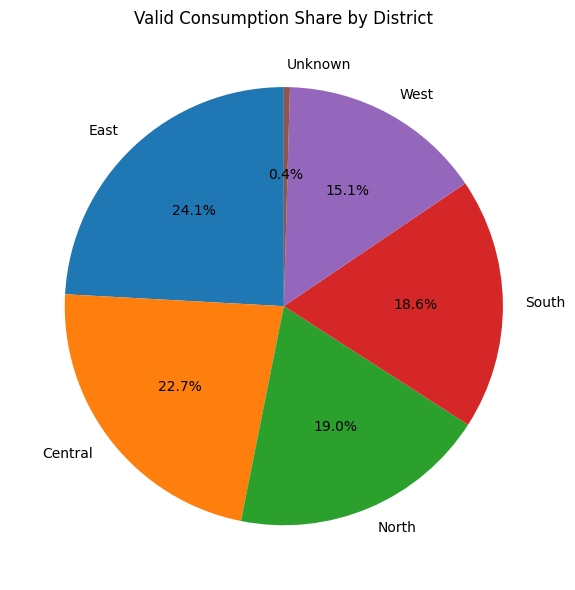

In [0]:
district_pdf = district_summary.orderBy(F.desc("district_consumption")).toPandas()
plt.figure(figsize=(8, 6))
plt.pie(district_pdf["district_consumption"], labels=district_pdf["district"].fillna("Unknown"), autopct="%1.1f%%", startangle=90)
plt.title("Valid Consumption Share by District")
plt.tight_layout()
plt.show()

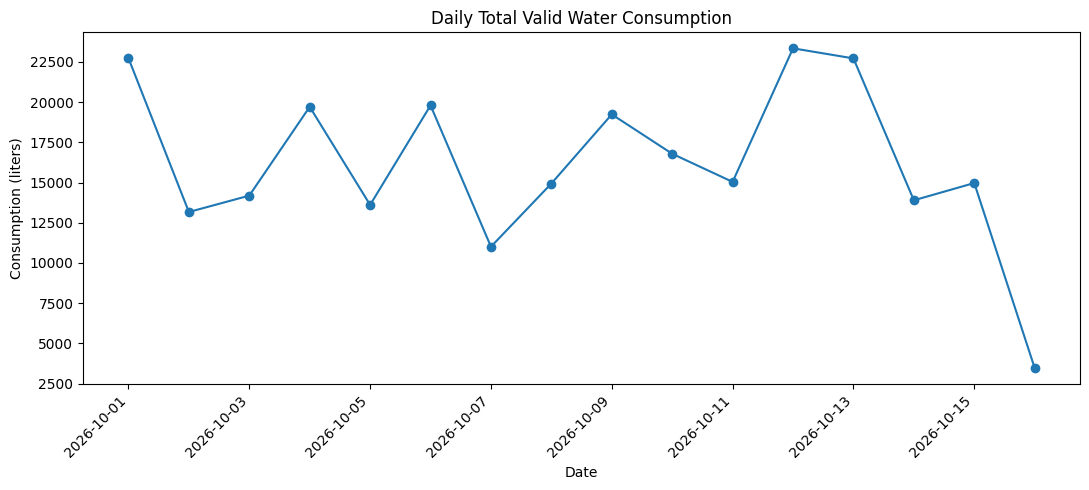

In [0]:
daily = (clean.withColumn("reading_date", F.to_date("reading_time"))
    .groupBy("reading_date")
    .agg(F.sum("consumption_liters").alias("daily_consumption"))
    .orderBy("reading_date"))
daily_pdf = daily.toPandas()
plt.figure(figsize=(11, 5))
plt.plot(daily_pdf["reading_date"], daily_pdf["daily_consumption"], marker="o")
plt.title("Daily Total Valid Water Consumption")
plt.xlabel("Date")
plt.ylabel("Consumption (liters)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [0]:
request_summary = (requests.groupBy("zone_id")
    .agg(F.count("*").alias("service_request_count"),
         F.sum(F.when(F.col("priority") == "High", 1).otherwise(0)).alias("high_priority_requests")))

final_report = (zone_summary
    .join(request_summary, "zone_id", "left")
    .fillna({"service_request_count": 0, "high_priority_requests": 0})
    .withColumn("low_pressure_flag", F.col("average_pressure_bar") < 2.5)
    .withColumn("chlorine_review_flag",
        (F.col("average_chlorine_mg_l") < 0.2) | (F.col("average_chlorine_mg_l") > 1.0)))

(final_report.write.format("delta").mode("overwrite").option("overwriteSchema", "true")
    .saveAsTable(f"{NS}.capstone_water_operations_report"))
display(final_report.orderBy(F.desc("high_priority_requests"), F.asc("average_pressure_bar")))


zone_id,total_valid_consumption,average_pressure_bar,average_chlorine_mg_l,reading_count,zone_name,city,district,zone_type,daily_capacity_liters,active,commissioned_on,service_request_count,high_priority_requests,low_pressure_flag,chlorine_review_flag
W02,24120,3.3061538461538458,0.6192307692307693,13,Hill View,Hyderabad,North,Residential,180000,true,2019-02-15,4,2,false,false
W01,23107,3.423076923076923,0.8200000000000002,13,Old City,Hyderabad,Central,Residential,240000,true,2018-01-15,4,2,false,false
W08,33689,2.8657142857142857,0.6185714285714284,14,Transit Hub,Hyderabad,East,Commercial,170000,true,2018-08-15,4,1,false,false
W03,35665,3.019999999999999,0.936153846153846,13,Market District,Hyderabad,Central,Commercial,210000,true,2020-03-15,3,1,false,false
W06,20212,3.160769230769231,0.6776923076923076,13,Industrial Estate,Hyderabad,South,Industrial,320000,true,2023-06-15,4,1,false,false
W04,18120,3.336153846153846,0.7861538461538461,13,Lake Side,Hyderabad,West,Mixed,280000,true,2021-04-15,3,1,false,false
W09,20894,3.5469230769230773,0.6815384615384615,13,Riverfront,Hyderabad,West,Mixed,230000,true,2019-01-15,4,1,false,false
W07,25104,3.5700000000000003,0.773076923076923,13,Garden Colony,Hyderabad,North,Residential,190000,true,2024-07-15,3,1,false,false
W05,28717,3.632857142857143,0.8735714285714286,14,University Quarter,Hyderabad,East,Institutional,150000,true,2022-05-15,4,1,false,false
W10,27808,3.717692307692307,0.7928571428571427,14,South Extension,Hyderabad,South,Residential,260000,true,2020-02-15,3,1,false,false


**Final capstone | Water Operations Analytics**

In [0]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

CATALOG = "sasi_008"
SCHEMA = "default"
NS = f"{CATALOG}.{SCHEMA}"

In [0]:
raw_current = spark.table(f"{NS}.water_meter_readings_source")
from pyspark.sql.window import Window
clean_window = Window.partitionBy("reading_id").orderBy(
    F.col("reading_time").desc_nulls_last(),
    F.col("consumption_liters").desc_nulls_last())
clean = (raw_current
    .filter((F.col("reading_status") == "Valid")
            & (F.col("flow_lpm") > 0)
            & (F.col("consumption_liters") > 0)
            & F.col("zone_id").isNotNull())
    .withColumn("_rn", F.row_number().over(clean_window))
    .filter(F.col("_rn") == 1)
    .drop("_rn"))
(clean.write.format("delta").mode("overwrite").option("overwriteSchema", "true")
    .saveAsTable(f"{NS}.water_readings_clean"))
zones = spark.table(f"{NS}.water_zones")
requests = spark.table(f"{NS}.water_service_requests")

In [0]:
zone_summary = (clean.groupBy("zone_id")
    .agg(F.sum("consumption_liters").alias("total_valid_consumption"),
         F.avg("pressure_bar").alias("average_pressure_bar"),
         F.avg("chlorine_mg_l").alias("average_chlorine_mg_l"),
         F.count("*").alias("reading_count"))
    .join(zones, "zone_id", "left"))

district_summary = (zone_summary.groupBy("district")
    .agg(F.sum("total_valid_consumption").alias("district_consumption")))

(zone_summary.write.format("delta").mode("overwrite").option("overwriteSchema", "true")
    .saveAsTable(f"{NS}.capstone_zone_summary"))
(district_summary.write.format("delta").mode("overwrite").option("overwriteSchema", "true")
    .saveAsTable(f"{NS}.capstone_district_summary"))

display(zone_summary.orderBy(F.desc("total_valid_consumption")))
display(district_summary.orderBy(F.desc("district_consumption")))

zone_id,total_valid_consumption,average_pressure_bar,average_chlorine_mg_l,reading_count,zone_name,city,district,zone_type,daily_capacity_liters,active,commissioned_on
W03,35665,3.019999999999999,0.936153846153846,13,Market District,Hyderabad,Central,Commercial,210000,true,2020-03-15
W08,33689,2.8657142857142857,0.6185714285714284,14,Transit Hub,Hyderabad,East,Commercial,170000,true,2018-08-15
W05,28717,3.632857142857143,0.8735714285714286,14,University Quarter,Hyderabad,East,Institutional,150000,true,2022-05-15
W10,27808,3.717692307692307,0.7928571428571427,14,South Extension,Hyderabad,South,Residential,260000,true,2020-02-15
W07,25104,3.5700000000000003,0.773076923076923,13,Garden Colony,Hyderabad,North,Residential,190000,true,2024-07-15
W02,24120,3.3061538461538458,0.6192307692307693,13,Hill View,Hyderabad,North,Residential,180000,true,2019-02-15
W01,23107,3.423076923076923,0.8200000000000002,13,Old City,Hyderabad,Central,Residential,240000,true,2018-01-15
W09,20894,3.5469230769230773,0.6815384615384615,13,Riverfront,Hyderabad,West,Mixed,230000,true,2019-01-15
W06,20212,3.160769230769231,0.6776923076923076,13,Industrial Estate,Hyderabad,South,Industrial,320000,true,2023-06-15
W04,18120,3.336153846153846,0.7861538461538461,13,Lake Side,Hyderabad,West,Mixed,280000,true,2021-04-15


district,district_consumption
East,62406
Central,58772
North,49224
South,48020
West,39014
null,1150


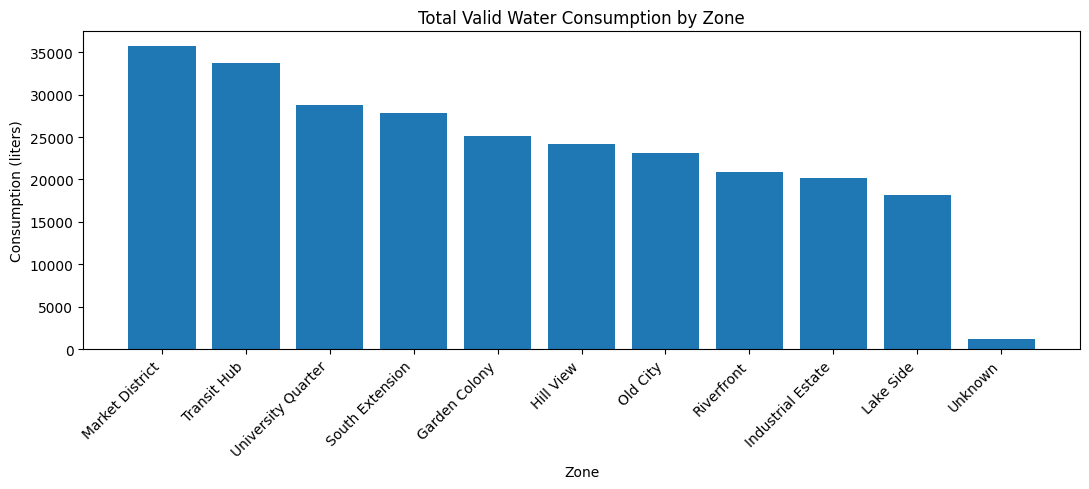

In [0]:
zone_pdf = zone_summary.select("zone_name", "total_valid_consumption").orderBy(F.desc("total_valid_consumption")).toPandas()
plt.figure(figsize=(11, 5))
plt.bar(zone_pdf["zone_name"].fillna("Unknown").astype(str), zone_pdf["total_valid_consumption"])
plt.title("Total Valid Water Consumption by Zone")
plt.xlabel("Zone")
plt.ylabel("Consumption (liters)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

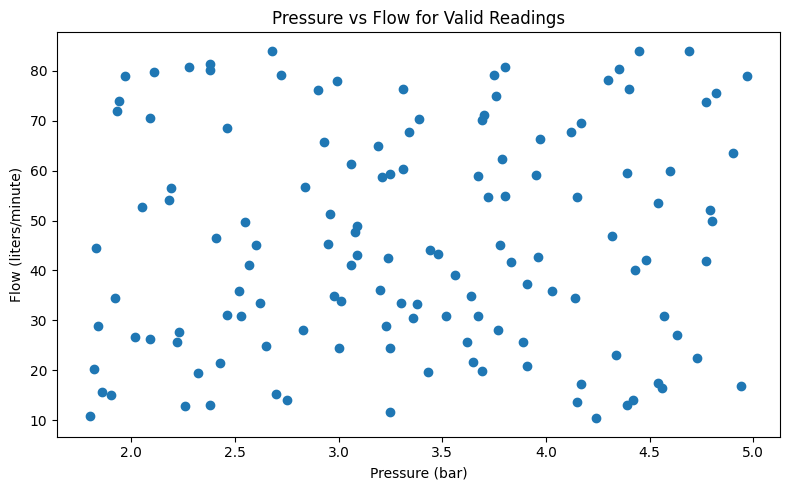

In [0]:
scatter_pdf = clean.select("pressure_bar", "flow_lpm").dropna().toPandas()
plt.figure(figsize=(8, 5))
plt.scatter(scatter_pdf["pressure_bar"], scatter_pdf["flow_lpm"])
plt.title("Pressure vs Flow for Valid Readings")
plt.xlabel("Pressure (bar)")
plt.ylabel("Flow (liters/minute)")
plt.tight_layout()
plt.show()